<a href="https://colab.research.google.com/github/A01286962/1-maap/blob/main/Class_10_Presentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Motor Vehicle Ocuppant Death per 100,000 Population analysis

### Table of Contents
1. [1. Setup](#scrollTo=xlbnjAt3kfdN)
2. [RQ 1: Which zone of states has more deaths, South, North, East or West?](#scrollTo=rmr7Rs-tlU5B)
   - [Box Plots](#scrollTo=YbqTmZSh8fHf)
3. [RQ 2: Has there been less deaths as time has passed?](#scrollTo=h0vv2Bekl0by)
   - [Bar Charts](#scrollTo=PzfNcTtm8lWt)
4. [RQ 3: Are there more male or female deaths in 2014?](#scrollTo=8878fdfd)
   - [Pie Chart](#scrollTo=LA7o_JJyAkZs)
5. [RQ 4: How are the overall occupant deaths distributed across states in 2014?](#scrollTo=2fc7b084)
   - [Histogram](#scrollTo=91ac1672)
6. [RQ 5: What is the proportion of deaths by zone subdivided by sex in 2014?](#scrollTo=a86076cb)
   - [Donut Chart](#scrollTo=010ce065)
7. [RQ 6: Is there a relationship between deaths of young adults and adults over 55 years old?](#scrollTo=b1e8ec24)
   - [Scatter Plot](#scrollTo=0c281f6a)
8. [RQ 7: Which states have the most difference in deaths from 2012 to 2014?](#scrollTo=b7b0194a)
   - [Waterfall Chart](#scrollTo=a3364ed3)
9. [RQ 8: How can we predict the deaths of 2014 based on deaths by male and female 2 years before?](#scrollTo=1d5eda51)
   - [Regression Model](#scrollTo=1d5eda51)

# 1. [Setup](#scrollTo=2Rte-oANkobI)

In [2]:
file_path = 'https://raw.githubusercontent.com/A01286962/1-maap/refs/heads/main/Motor_Vehicle_Occupant_Death_Rate%2C_by_Age_and_Sex%2C_2012_%26_2014%2C_All_States_20261006.csv?token=GHSAT0AAAAAAEJ43LNZM5WSV7WIT6FTKUSS2W34OKQ'
import pandas as pd
import numpy as np
df = pd.read_csv(file_path)
df.head()

,State,Location,"All Ages, 2012","All Ages, 2014","Age 0-20, 2012","Age 0-20, 2014","Age 21-34, 2012","Age 21-34, 2014","Age 35-54, 2012","Age 35-54, 2014","Age 55+, 2012","Age 55+, 2014","Male, 2012","Male, 2014","Female, 2012","Female, 2014"
0,Alabama,"Alabama (32.839182, -86.631125)",13.7,13.0,8.6,6.9,20.8,17.8,12.6,14.2,15.5,14.6,17.6,17.2,10.0,9.0
1,Alaska,"Alaska (64.836661, -147.738891)",5.4,5.9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.5,7.5,NaN,NaN
2,Arizona,"Arizona (34.869712, -111.760902)",7.4,6.0,5.0,3.4,12.0,8.4,7.3,6.0,6.9,6.9,10.2,7.3,4.7,4.8
3,Arkansas,"Arkansas (34.748745, -92.275105)",13.8,12.0,8.0,6.2,20.3,15.1,13.8,13.6,16.2,14.0,17.3,16.0,10.4,8.1
4,California,"California (37.640735, -121.002435)",4.2,4.3,2.4,2.7,6.9,6.9,4.0,3.5,4.5,4.7,5.6,5.7,2.7,2.8


In [3]:
df.columns

Index(['State', 'Location', 'All Ages, 2012', 'All Ages, 2014',
       'Age 0-20, 2012', 'Age 0-20, 2014', 'Age 21-34, 2012',
       'Age 21-34, 2014', 'Age 35-54, 2012', 'Age 35-54, 2014',
       'Age 55+, 2012', 'Age 55+, 2014', 'Male, 2012', 'Male, 2014',
       'Female, 2012', 'Female, 2014'],
      dtype='object')

In [4]:
favs = ['State', 'All Ages, 2012', 'All Ages, 2014','Female, 2012',
    'Female, 2014',
    'Male, 2012',
    'Male, 2014']

In [5]:
ndf = df[favs].copy()
ndf = ndf[~ndf['State'].isin(['United States', 'District of Columbia'])]
ndf = ndf.dropna()
ndf.head()

,State,"All Ages, 2012","All Ages, 2014","Female, 2012","Female, 2014","Male, 2012","Male, 2014"
0,Alabama,13.7,13.0,10.0,9.0,17.6,17.2
2,Arizona,7.4,6.0,4.7,4.8,10.2,7.3
3,Arkansas,13.8,12.0,10.4,8.1,17.3,16.0
4,California,4.2,4.3,2.7,2.8,5.6,5.7
5,Colorado,5.8,6.0,4.1,4.4,7.4,7.5


In [6]:
ndf = ndf.rename(columns={
    'All Ages, 2012': 'deaths_2012',
    'All Ages, 2014': 'deaths_2014',
    'Female, 2012': 'deaths_fem_2012',
    'Female, 2014': 'deaths_fem_2014',
    'Male, 2012': 'deaths_male_2012',
    'Male, 2014': 'deaths_male_2014',
    'Age 0-20, 2014': 'Age_0-20_2014',
    'Age 21-34, 2014' : 'Age_21-34_2014',
    'Age 35-54, 2014' : 'Age_35-54_2014',
    'Age 55+, 2014' : 'Age_55+_2014'
})
ndf.head()

,State,deaths_2012,deaths_2014,deaths_fem_2012,deaths_fem_2014,deaths_male_2012,deaths_male_2014
0,Alabama,13.7,13.0,10.0,9.0,17.6,17.2
2,Arizona,7.4,6.0,4.7,4.8,10.2,7.3
3,Arkansas,13.8,12.0,10.4,8.1,17.3,16.0
4,California,4.2,4.3,2.7,2.8,5.6,5.7
5,Colorado,5.8,6.0,4.1,4.4,7.4,7.5


In [7]:
ndf.shape

(46, 7)

In [8]:
ndf.dtypes

,0
State,object
deaths_2012,float64
deaths_2014,float64
deaths_fem_2012,float64
deaths_fem_2014,float64
deaths_male_2012,float64
deaths_male_2014,float64


In [9]:
age_cols = ['State', 'Age 0-20, 2014', 'Age 21-34, 2014', 'Age 35-54, 2014', 'Age 55+, 2014']
age_df = df[age_cols].copy()
age_df = age_df[~age_df['State'].isin(['United States', 'District of Columbia'])]
age_df = age_df.dropna()

age_melted = age_df.melt(id_vars='State', var_name='Age Group', value_name='Death Rate')
age_melted['Age Group'] = age_melted['Age Group'].str.replace(', 2014', '')

## Description of the Dataset

The dataset gives the amount of deaths per 100,000, given the year, the state where the death ocurred and the sex.


### Description of variable of interest

- `State` : State of USA in which the death happened. This is a categorical variable.

- `deaths_2012`: Deaths per 100,000 population in automobile accidents that happened in 2012 disregarding the age group. This is a numerical variable.

- `deaths_2014`: Deaths per 100,000 population in automobile accidents that happened in 2014 disregarding the age group. This is a numerical variable.

- `deaths_fem_2012`: Deaths per 100,000 population in automobile accidents for females in 2012. This is a numerical variable.

- `deaths_fem_2014` : Deaths per 100,000 population in automobile accidents for females in 2014. This is a numerical variable.

- `deaths_male_2012` : Deaths per 100,000 population in automobile accidents for males in 2012. This is a numerical variable.

- `deaths_male_2014` : Deaths per 100,000 population in automobile accidents for males in 2014. This is a numerical variable.

- `Age_0-20_2014` : Deaths per 100,000 population in automobile accidents for people aged 0 to 20 years old in 2014. This is a numerical variable.

- `Age_21-34_2014` : Deaths per 100,000 population in automobile accidents for people aged 21 to 34 years old in 2014. This is a numerical variable.

- `Age_35-54_2014` : Deaths per 100,000 population in automobile accidents for people aged 35 to 54 years old in 2014. This is a numerical variable.

- `Age_55+_2014` : Deaths per 100,000 population in automobile accidents for people aged 55 or more years old in 2014. This is a numerical variable.









# [RQ 1: Which zone of states has more deaths, South, North, East or West?](#scrollTo=2Rte-oANkobI)

In [10]:
def cus_cls(x):
    north_states = [
        "Maine", "New Hampshire", "Vermont", "Massachusetts",
        "Rhode Island", "Connecticut", "New York", "New Jersey",
        "Pennsylvania", "Michigan", "Wisconsin", "Minnesota",
        "Iowa", "North Dakota", "South Dakota", "Nebraska",
        "Montana", "Wyoming", "Idaho", "Washington", "Oregon"
    ]

    south_states = [
        "Delaware", "Maryland", "Virginia", "West Virginia",
        "North Carolina", "South Carolina", "Georgia", "Florida",
        "Kentucky", "Tennessee", "Mississippi", "Alabama",
        "Arkansas", "Louisiana", "Oklahoma", "Texas"
    ]

    east_states = [
        "Ohio", "Indiana", "Illinois", "Missouri",
        "Florida", "Georgia", "South Carolina", "North Carolina",
        "Virginia", "Maryland", "Delaware", "New Jersey",
        "New York", "Connecticut", "Rhode Island", "Massachusetts",
        "Vermont", "New Hampshire", "Maine", "Pennsylvania",
        "West Virginia", "Kentucky", "Tennessee"
    ]

    west_states = [
        "Alaska", "Hawaii", "California", "Oregon", "Washington",
        "Nevada", "Arizona", "Utah", "Idaho", "Montana", "Wyoming",
        "Colorado", "New Mexico", "Texas", "Oklahoma", "Kansas",
        "Nebraska", "South Dakota", "North Dakota", "Minnesota"
    ]

    if x in north_states:
        return 'North'
    elif x in south_states:
        return 'South'
    elif x in east_states:
        return 'East'
    elif x in west_states:
        return 'West'
    else:
        return 'Unknown'

In [11]:
ndf ['Location'] = ndf['State'].apply(cus_cls)
ndf.head()


,State,deaths_2012,deaths_2014,deaths_fem_2012,deaths_fem_2014,deaths_male_2012,deaths_male_2014,Location
0,Alabama,13.7,13.0,10.0,9.0,17.6,17.2,South
2,Arizona,7.4,6.0,4.7,4.8,10.2,7.3,West
3,Arkansas,13.8,12.0,10.4,8.1,17.3,16.0,South
4,California,4.2,4.3,2.7,2.8,5.6,5.7,West
5,Colorado,5.8,6.0,4.1,4.4,7.4,7.5,West


In [12]:
location_direction_sum = pd.pivot_table(ndf, index='Location', values = 'deaths_2014' , aggfunc='sum')
location_direction_sum

,deaths_2014
Location,
East,28.9
North,148.6
South,163.9
West,49.8


# [FIGURE 1](#scrollTo=2Rte-oANkobI)

/tmp/ipykernel_1199/980638596.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=ndf, x='Location', y='deaths_2014', palette='Set2')


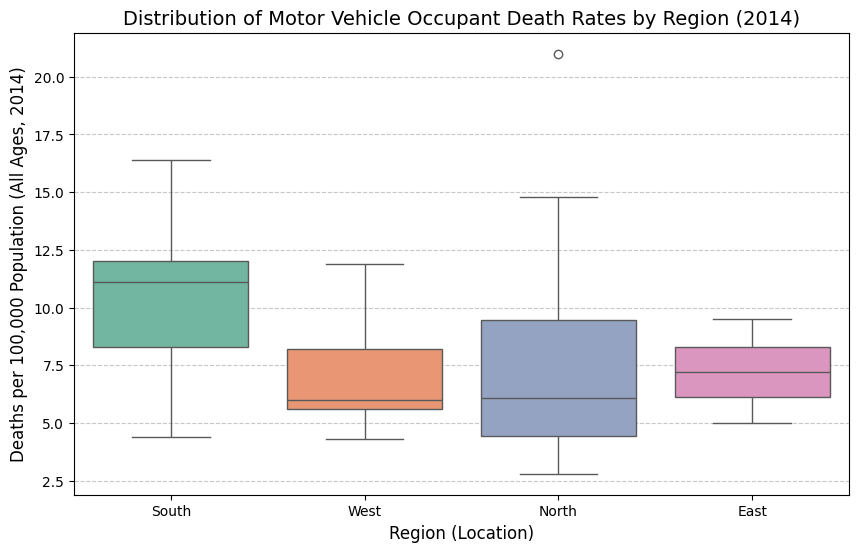

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns


ndf['Location'] = ndf['State'].apply(cus_cls)

plt.figure(figsize=(10, 6))
sns.boxplot(data=ndf, x='Location', y='deaths_2014', palette='Set2')

plt.title('Distribution of Motor Vehicle Occupant Death Rates by Region (2014)', fontsize=14)
plt.xlabel('Region (Location)', fontsize=12)
plt.ylabel('Deaths per 100,000 Population (All Ages, 2014)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# [Insights For Question 1](#scrollTo=2Rte-oANkobI)

- `Insight 1`

South has higher overall deaths than any other zone, also shows the highest median of deaths per state.

- `Insight 2`

North shows the highest value of deaths at around 21.5 deaths which is considered an outlier and is not close to the box plot of the zone.

# [RQ 2: Has there been less deaths as time has passed?](#scrollTo=2Rte-oANkobI)

In [14]:
deaths_2012 = ndf['deaths_2012'].sum()
deaths_2014 = ndf['deaths_2014'].sum()
decrease_deaths_percent = -100 * ((deaths_2014 / deaths_2012) - 1)

print(f"  MOTOR VEHICLE OCCUPANT DEATH RATE SUMMARY  ")
print(f"Total Death Rate (2012):  {deaths_2012:>8.1f} per 100k")
print(f"Total Death Rate (2014):  {deaths_2014:>8.1f} per 100k")
print(f"Percentage Decrease:       {decrease_deaths_percent:>7.2f}%")

  MOTOR VEHICLE OCCUPANT DEATH RATE SUMMARY  
Total Death Rate (2012):     405.0 per 100k
Total Death Rate (2014):     391.2 per 100k
Percentage Decrease:          3.41%


# [Figure 2](#scrollTo=2Rte-oANkobI)


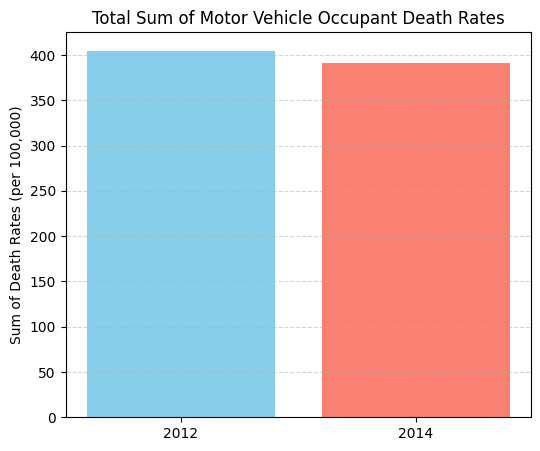

In [15]:
total_deaths_2012 = ndf['deaths_2012'].sum()
total_deaths_2014 = ndf['deaths_2014'].sum()

plt.figure(figsize=(6, 5))
plt.bar(['2012', '2014'], [total_deaths_2012, total_deaths_2014], color=['skyblue', 'salmon'])
plt.title('Total Sum of Motor Vehicle Occupant Death Rates')
plt.ylabel('Sum of Death Rates (per 100,000)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

# [Insights For Question 2](#scrollTo=2Rte-oANkobI)

- `Insight 1`

There are less deaths in 2014 (391.2) than in 2012 (405)

- `Insight 2`

Deaths decreased 3.41% over the course of 2 years for unknown reasons

# [RQ 3: Are there more male or female deaths in 2014?](#scrollTo=2Rte-oANkobI)

# [FIGURE 3](#scrollTo=2Rte-oANkobI)

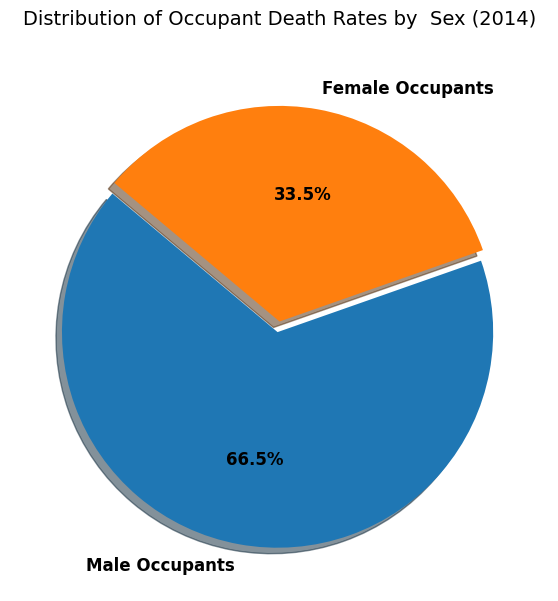

In [16]:

male_deaths_total = ndf['deaths_male_2014'].sum()
female_deaths_total = ndf['deaths_fem_2014'].sum()

labels = ['Male Occupants', 'Female Occupants']
sizes = [male_deaths_total, female_deaths_total]
colors = ['#1f77b4', '#ff7f0e']
explode = (0.05, 0)

plt.figure(figsize=(7, 7))
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%',
        shadow=True, startangle=140, textprops={'fontsize': 12, 'weight': 'bold'})
plt.title('Distribution of Occupant Death Rates by  Sex (2014)', fontsize=14, pad=20)
plt.show()

### [Insights For Question 3](#scrollTo=2Rte-oANkobI)

- `Insight 1`

There were almost double the death of men than deaths of women in 2014

# [RQ 4: How are the overall occupant deaths distributed across states in 2014?](#scrollTo=2Rte-oANkobI)

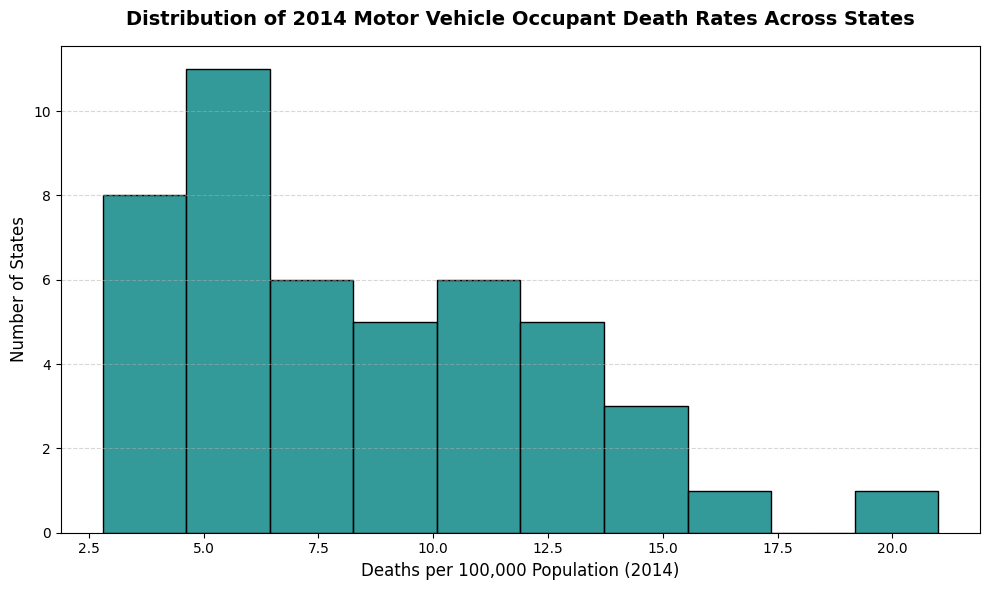

In [17]:


plt.figure(figsize=(10, 6))

sns.histplot(data=ndf, x='deaths_2014', bins=10, color='teal', edgecolor='black', alpha=0.8)

plt.title('Distribution of 2014 Motor Vehicle Occupant Death Rates Across States', fontsize=14, weight='bold', pad=15)
plt.xlabel('Deaths per 100,000 Population (2014)', fontsize=12)
plt.ylabel('Number of States', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### [Insights For Question 4](#scrollTo=2Rte-oANkobI)

- `Insight 1`

The distribution is right-skewed, meaning most states cluster around lower death rates (between 4 and 10 deaths per 100k population), while only a few outlier states have exceptionally high occupant death rates above 15 per 100k.

- `Insight 2`

The mode group consists of states with roughly 5 to 7.5 deaths per 100k, showing that a majority of states experience relatively safer traffic environments compared to extreme outlying areas.
```

# [RQ 5: What is the proportion of deaths by zone subdivided by sex in 2014?](#scrollTo=2Rte-oANkobI)

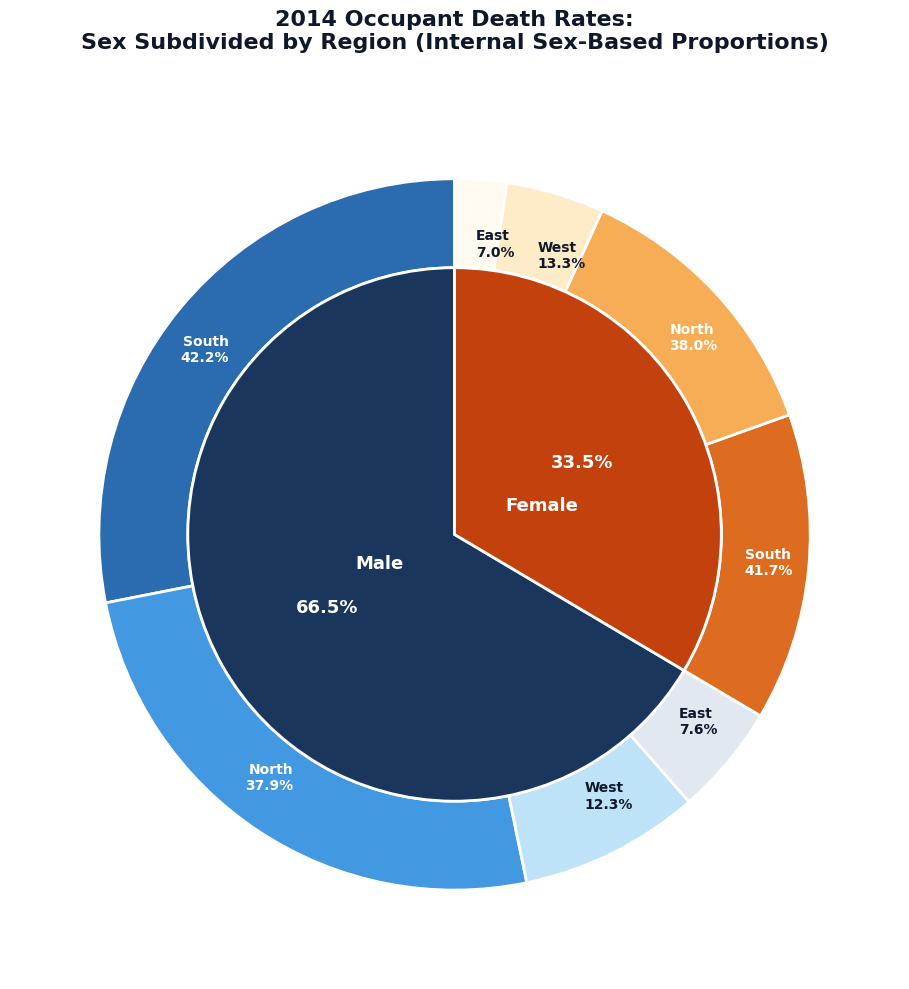

In [18]:
male_total = ndf['deaths_male_2014'].sum()
female_total = ndf['deaths_fem_2014'].sum()

regions = ['South', 'North', 'West', 'East']
male_regional = [ndf[ndf['Location'] == r]['deaths_male_2014'].sum() for r in regions]
female_regional = [ndf[ndf['Location'] == r]['deaths_fem_2014'].sum() for r in regions]

inner_sizes = [male_total, female_total]
inner_labels = ['Male', 'Female']
inner_colors = ['#1a365d', '#c2410c']

outer_sizes = male_regional + female_regional
outer_labels = []
for r, val in zip(regions, male_regional):
    outer_labels.append(f"{r}\n{val/male_total*100:.1f}%")
for r, val in zip(regions, female_regional):
    outer_labels.append(f"{r}\n{val/female_total*100:.1f}%")

male_shades = ['#2b6cb0', '#4299e1', '#bee3f8', '#e2e8f0']
female_shades = ['#dd6b20', '#f6ad55', '#feebc8', '#fffaf0']
outer_colors = male_shades + female_shades

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(aspect="equal"))

outer_wedges, outer_texts = ax.pie(
    outer_sizes, radius=1.0,
    labels=outer_labels, labeldistance=0.82,
    colors=outer_colors,
    startangle=90,
    textprops=dict(fontsize=10, weight="bold"),
    wedgeprops=dict(width=0.25, edgecolor='white', linewidth=2)
)

inner_wedges, inner_texts, inner_autotexts = ax.pie(
    inner_sizes, radius=0.75,
    colors=inner_colors,
    labels=inner_labels,
    autopct='%1.1f%%', pctdistance=0.55,
    startangle=90, labeldistance=0.22,
    textprops=dict(color="white", fontsize=13, weight="bold"),
    wedgeprops=dict(width=0.75, edgecolor='white', linewidth=2)
)

for i, text in enumerate(outer_texts):
    if i in [0, 1, 4, 5]:
        text.set_color('white')
    else:
        text.set_color('#0f172a')

plt.title('2014 Occupant Death Rates:\nSex Subdivided by Region (Internal Sex-Based Proportions)', fontsize=16, pad=30, weight='bold', color='#0f172a')
plt.tight_layout()
plt.show()

### [Insights For Question 5](#scrollTo=2Rte-oANkobI)

- `Insight 1`

The distribution of deaths by zones is very alike for both sexes male and female.

# [RQ 6: Is there a relationship between deaths of young adults and adults over 55 years old?](#scrollTo=2Rte-oANkobI)

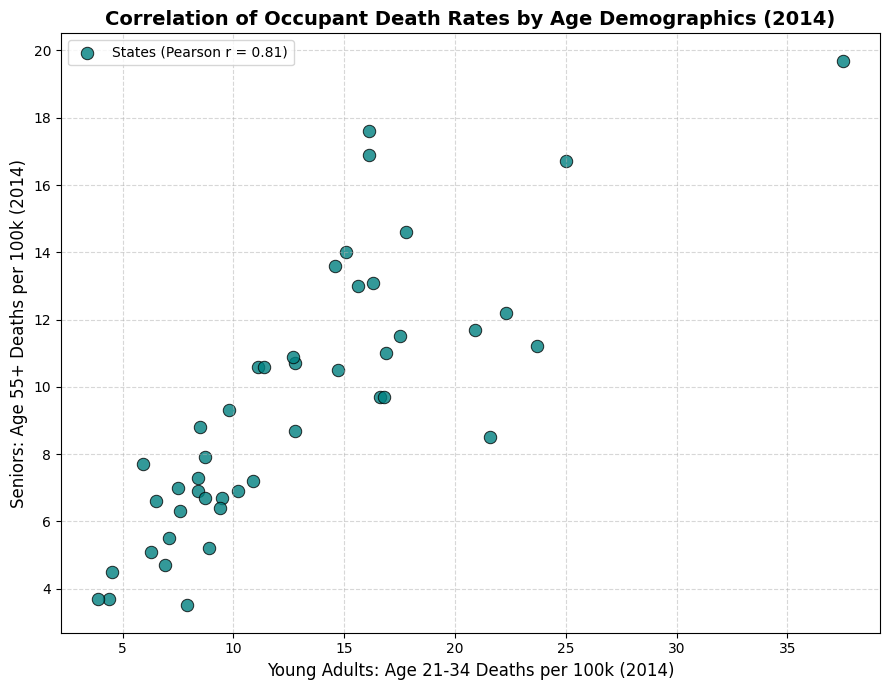

In [19]:

from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import seaborn as sns

ndf['Age_21-34_2014'] = df['Age 21-34, 2014']
ndf['Age_55+_2014'] = df['Age 55+, 2014']

plot_df = ndf[['Age_21-34_2014', 'Age_55+_2014']].dropna()

r_val, p_val = pearsonr(plot_df['Age_21-34_2014'], plot_df['Age_55+_2014'])

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=plot_df,
    x='Age_21-34_2014',
    y='Age_55+_2014',
    color='teal',
    s=80,
    alpha=0.8,
    edgecolor='black',
    label=f'States (Pearson r = {r_val:.2f})'
)

plt.title('Correlation of Occupant Death Rates by Age Demographics (2014)', fontsize=14, weight='bold')
plt.xlabel('Young Adults: Age 21-34 Deaths per 100k (2014)', fontsize=12)
plt.ylabel('Seniors: Age 55+ Deaths per 100k (2014)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()

### [Insights For Question 6](#scrollTo=2Rte-oANkobI)

- `Insight 1`

There is a strong positive linear correlation for deaths between young adults and senior adults.

# [RQ 7: Which states have the most difference in deaths from 2012 to 2014?](#scrollTo=2Rte-oANkobI)

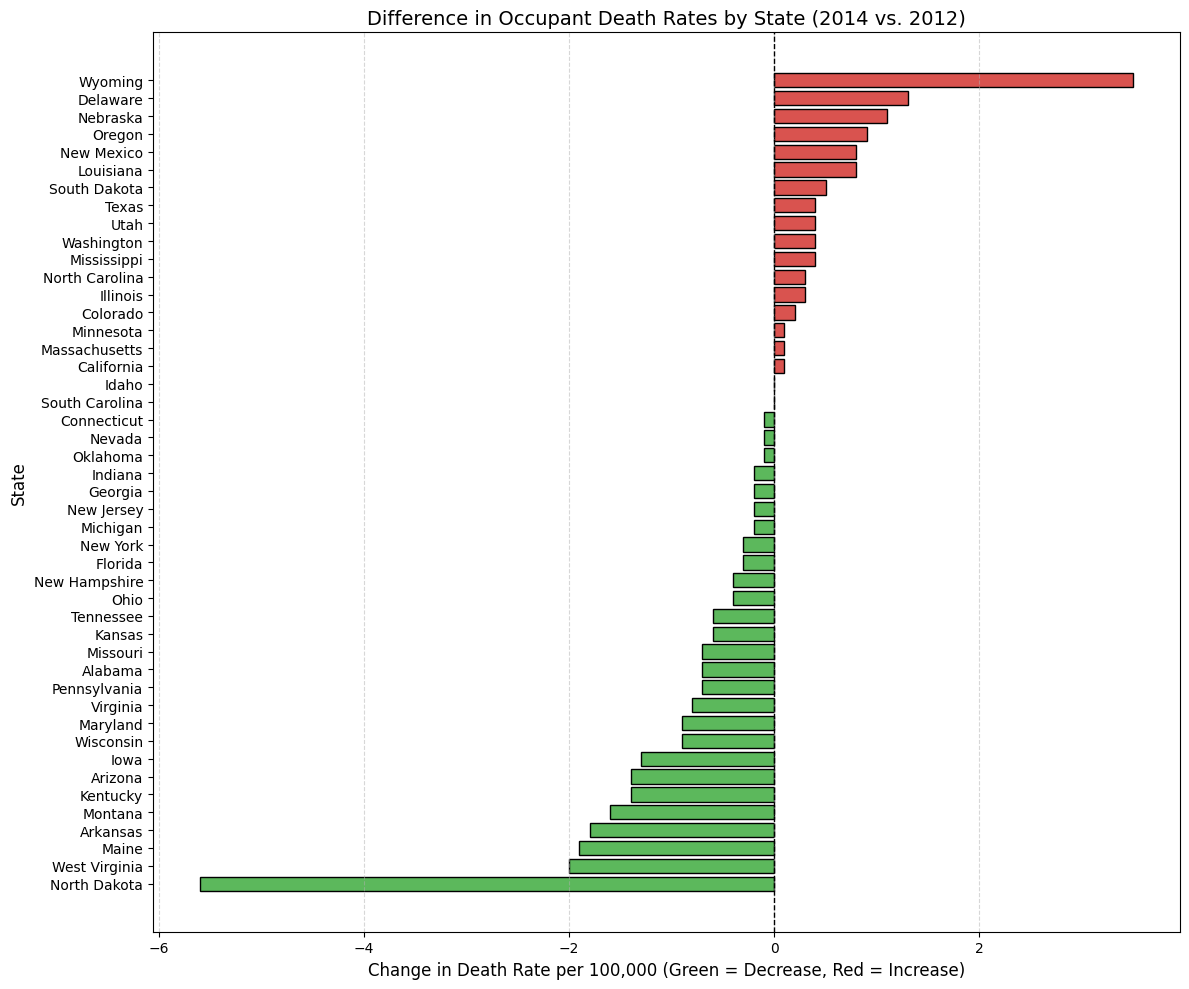

In [20]:
ndf['rate_diff'] = ndf['deaths_2014'] - ndf['deaths_2012']
sorted_diff = ndf.sort_values(by='rate_diff').copy()

sorted_diff['color'] = ['#d9534f' if x > 0 else '#5cb85c' for x in sorted_diff['rate_diff']]

plt.figure(figsize=(12, 10))
plt.barh(sorted_diff['State'], sorted_diff['rate_diff'], color=sorted_diff['color'], edgecolor='black')
plt.axvline(0, color='black', linewidth=1, linestyle='--')

plt.title('Difference in Occupant Death Rates by State (2014 vs. 2012)', fontsize=14)
plt.xlabel('Change in Death Rate per 100,000 (Green = Decrease, Red = Increase)', fontsize=12)
plt.ylabel('State', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### [Insights For Question 7](#scrollTo=2Rte-oANkobI)

- `Insight 1`

Wyoming Showed the highest increase in deaths from 2012 to 2014

- `Insight 2`

States like North Carolina and Idaho showed essentially no change in death amount over the 2 years.

# [RQ 8: How can we predict the deaths of 2014 based on deaths by male and female 2 years before?](#scrollTo=2Rte-oANkobI)

# deaths_2014 = β₀ + β₁(deaths_male_2012) + β₂(deaths_female_2012)

In [21]:
import statsmodels.api as sm

reg_df = ndf[['deaths_2014', 'deaths_male_2012', 'deaths_fem_2012']].dropna()

X = reg_df[['deaths_male_2012', 'deaths_fem_2012']]
y = reg_df['deaths_2014']

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            deaths_2014   R-squared:                       0.930
Model:                            OLS   Adj. R-squared:                  0.926
Method:                 Least Squares   F-statistic:                     284.5
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           1.60e-25
Time:                        22:45:38   Log-Likelihood:                -67.106
No. Observations:                  46   AIC:                             140.2
Df Residuals:                      43   BIC:                             145.7
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                0.1468      0.386  

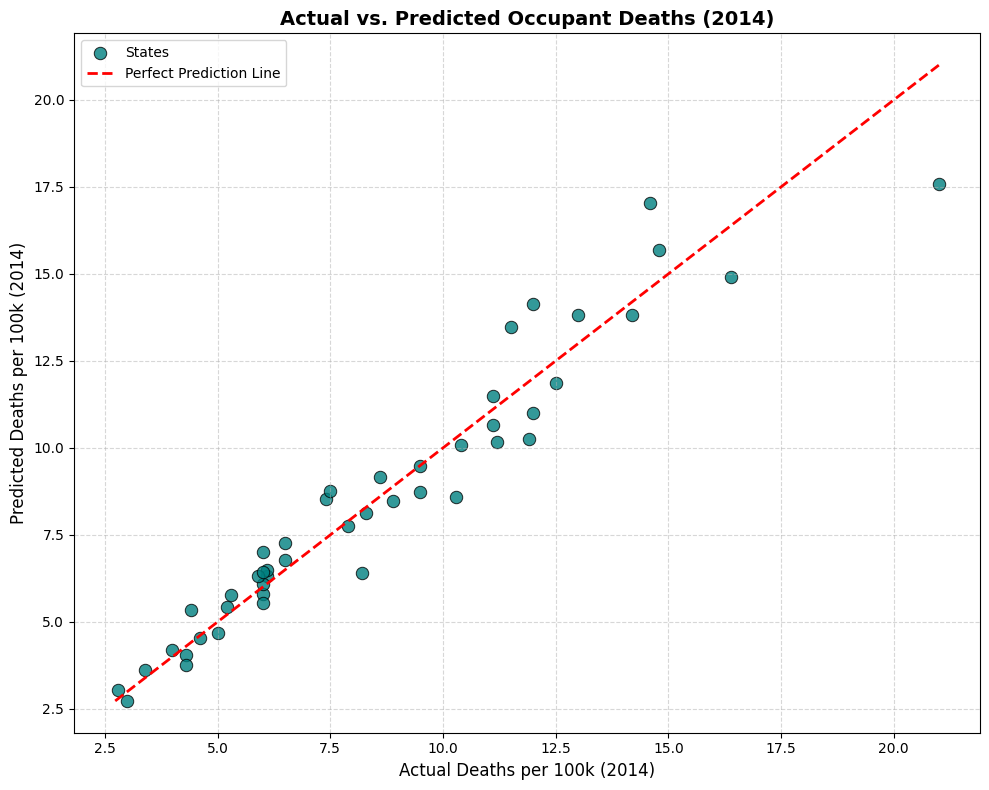

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

reg_df['predicted_deaths_2014'] = model.predict(X)

plt.figure(figsize=(10, 8))
sns.scatterplot(
    data=reg_df,
    x='deaths_2014',
    y='predicted_deaths_2014',
    color='teal',
    s=80,
    alpha=0.8,
    edgecolor='black',
    label='States'
)

min_val = min(reg_df['deaths_2014'].min(), reg_df['predicted_deaths_2014'].min())
max_val = max(reg_df['deaths_2014'].max(), reg_df['predicted_deaths_2014'].max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', lw=2, label='Perfect Prediction Line')

plt.title('Actual vs. Predicted Occupant Deaths (2014)', fontsize=14, weight='bold')
plt.xlabel('Actual Deaths per 100k (2014)', fontsize=12)
plt.ylabel('Predicted Deaths per 100k (2014)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()

In [30]:


male_deaths_2012_input = 11 #@param {type:"number"}
female_deaths_2012_input = 15 #@param {type:"number"}


custom_inputs = [1.0, male_deaths_2012_input, female_deaths_2012_input]

# Get prediction using model parameters
predicted_value = model.predict(custom_inputs)[0]

print("--------------------------------------------------")
print(f"  PREDICTION RESULTS USING REGRESSION MODEL       ")
print("--------------------------------------------------")
print(f"Input Male Death Rate (2012):   {male_deaths_2012_input:.2f} per 100k")
print(f"Input Female Death Rate (2012): {female_deaths_2012_input:.2f} per 100k")
print(f"deaths_2014 = β₀ + β₁(deaths_male_2012) + β₂(deaths_female_2012)")
print("--------------------------------------------------")
print(f" {predicted_value:.2f} = 0.1468 + 0.2332({male_deaths_2012_input:.2f}) + 0.9569({female_deaths_2012_input:.2f})")
print("--------------------------------------------------")
print("The total predicted deaths in 2014 given our inputs are:")
print(f"  {predicted_value:.2f} per 100k")

--------------------------------------------------
  PREDICTION RESULTS USING REGRESSION MODEL       
--------------------------------------------------
Input Male Death Rate (2012):   11.00 per 100k
Input Female Death Rate (2012): 15.00 per 100k
deaths_2014 = β₀ + β₁(deaths_male_2012) + β₂(deaths_female_2012)
--------------------------------------------------
 17.06 = 0.1468 + 0.2332(11.00) + 0.9569(15.00)
--------------------------------------------------
The total predicted deaths in 2014 given our inputs are:
  17.06 per 100k


### [Insights For Question 8](#scrollTo=2Rte-oANkobI)

- `Insight 1`

The model predicts the occupant death rates of 2014 with an R-squared of 0.930 using 2012 male and female death variables.

- `Insight 2`

Female deaths in 2012 is a more important predictor compared to 2012 male deaths.

## Conclusion

### 1. Most Important Findings from the Complete Analysis
* **Regional Disparities:** The Southern United States shows a higher rate of motor vehicle occupant deaths, both in total and median rates, than any other region.
* **Sex-Based Disproportionality:** Men showed for nearly double (66.5%) the occupant deaths compared to women (33.5%) in 2014.

### 2. Common Patterns Across Studies
* **Consistent Regional Profiles:** The relative proportion of deaths across regions (South, North, West, East) remains highly consistent regardless of demographic subsets.

* **Generational Correlation:** State level death rates for young adults (ages 21–34) are strongly and positively correlated with those of senior adults (ages 55+) with a Pearson correlation of $r = 0.81$.

### 3. Unexpected or Highly Important Results

* **Predictive Value of Female Deaths:** In the predictive regression model ($R^2 = 0.93$), the  2012 rate of female deaths in 2012 proved to be a statistically more powerful predictor of 2014 death rates than the 2012 rate of male deaths, despite men suffering a vastly higher overall volume of deaths.

* **Northern Outlier:** While the North generally has lower median death rates, it contained the single highest outlier state in 2014 (above 20 deaths per 100k).

### 4. Practical Conclusions

* **Targeted Regional Interventions:** Roadway safety and infrastructure campaigns should focus mainly on the South to address issues driving high regional rates.

* **General State Policies:** Given young adult and senior death rates are highly correlated, a state level intervention (such as improved lighting, better signage, and stricter enforcement) will likely yield safety benefits across multiple generations simultaneously.

### 5. Important Limitations to Consider

* **Short Time Horizon:** The data shows only two years (2012 and 2014), limiting our ability to establish long term trends or to confirm whether the decrease in deaths is part of a downward trajectory.

* **Lack of General Variables:** The regression and correlation analyses do not analyze for external parameters such as average miles traveled, weather conditions, urban to rural ratios, or state speed limits and seat belt laws.